In [2]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, classification_report)
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

os.makedirs("images", exist_ok=True)
sns.set_style("whitegrid")
tf.random.set_seed(42); np.random.seed(42)

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")   # ACQUIRE
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
print(df.describe())
print("Duplicates:", df.duplicated().sum())
print(df.isnull().sum())
print(df["Churn"].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
# TotalCharges is text because ~11 rows are blank (customers with tenure = 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

df = df.drop_duplicates()
df = df.drop(columns=["customerID"])          # ID has no predictive value

# Merge redundant categories
df = df.replace({"No internet service": "No", "No phone service": "No"})

# Outlier check (IQR method)
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n} outliers")
# Decide and justify in the report (they are likely genuine values, so keep them)

df_clean = df.copy()   # keep readable version for visualizations

Missing TotalCharges: 11
tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 0 outliers


/tmp/ipykernel_431/4056594120.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="Churn", palette="Set2")


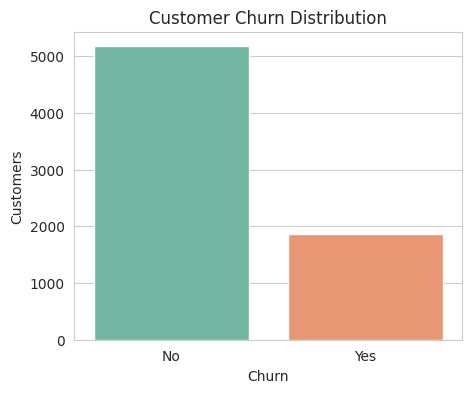

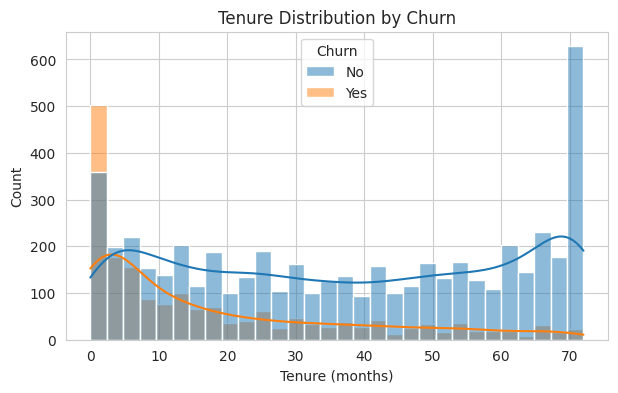

/tmp/ipykernel_431/4056594120.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges", palette="Set2")


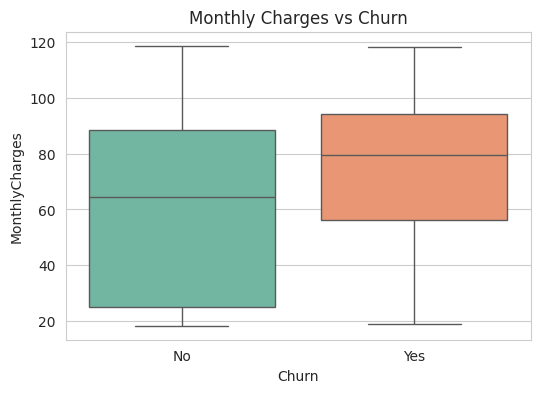

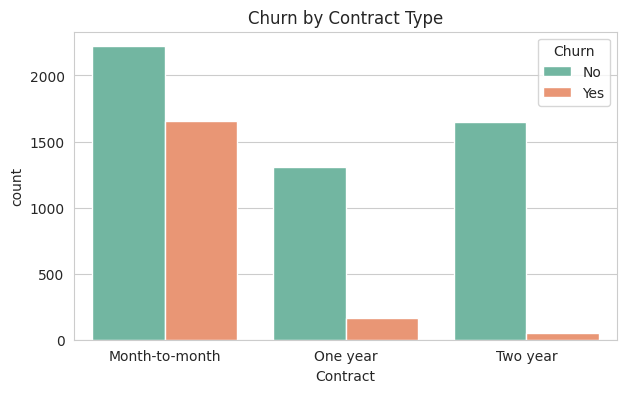

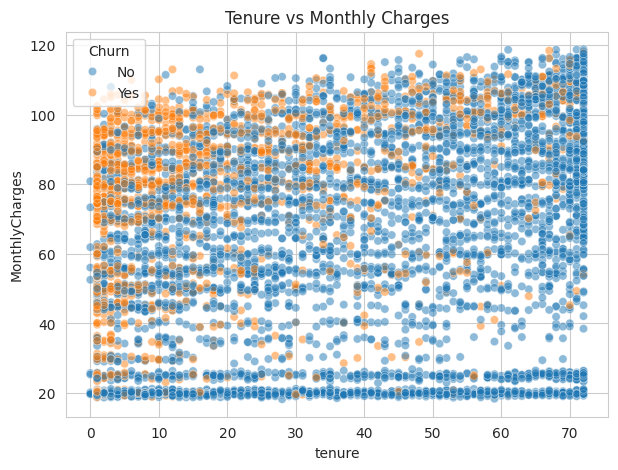

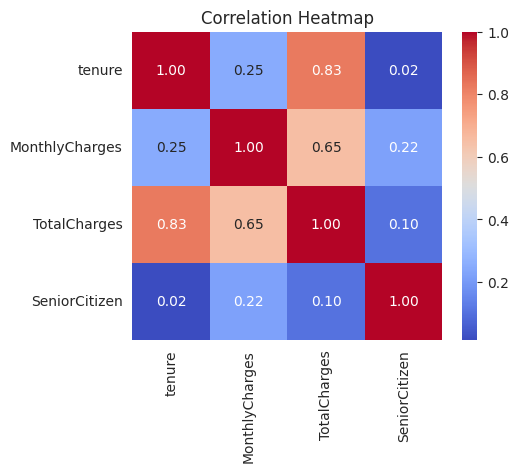

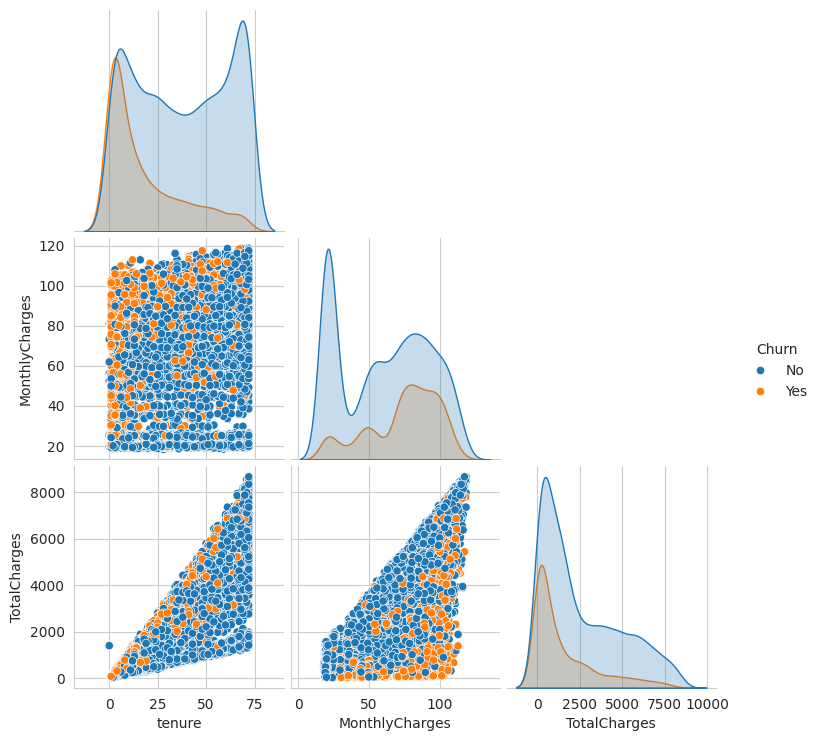

In [5]:
# V1: Target distribution
plt.figure(figsize=(5,4))
sns.countplot(data=df_clean, x="Churn", palette="Set2")
plt.title("Customer Churn Distribution"); plt.xlabel("Churn"); plt.ylabel("Customers")
plt.savefig("images/v1_churn_count.png", dpi=150, bbox_inches="tight"); plt.show()

# V2: Tenure histogram by churn
plt.figure(figsize=(7,4))
sns.histplot(data=df_clean, x="tenure", hue="Churn", kde=True, bins=30)
plt.title("Tenure Distribution by Churn"); plt.xlabel("Tenure (months)")
plt.savefig("images/v2_tenure_hist.png", dpi=150, bbox_inches="tight"); plt.show()

# V3: Boxplot of monthly charges
plt.figure(figsize=(6,4))
sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges", palette="Set2")
plt.title("Monthly Charges vs Churn")
plt.savefig("images/v3_box_monthly.png", dpi=150, bbox_inches="tight"); plt.show()

# V4: Contract type vs churn
plt.figure(figsize=(7,4))
sns.countplot(data=df_clean, x="Contract", hue="Churn", palette="Set2")
plt.title("Churn by Contract Type")
plt.savefig("images/v4_contract.png", dpi=150, bbox_inches="tight"); plt.show()

# V5: Scatterplot
plt.figure(figsize=(7,5))
sns.scatterplot(data=df_clean, x="tenure", y="MonthlyCharges", hue="Churn", alpha=.5)
plt.title("Tenure vs Monthly Charges")
plt.savefig("images/v5_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

# V6: Correlation heatmap (numeric columns)
plt.figure(figsize=(5,4))
sns.heatmap(df_clean[["tenure","MonthlyCharges","TotalCharges","SeniorCitizen"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.savefig("images/v6_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

# V7: Pairplot
sns.pairplot(df_clean[["tenure","MonthlyCharges","TotalCharges","Churn"]], hue="Churn", corner=True)
plt.savefig("images/v7_pairplot.png", dpi=150, bbox_inches="tight"); plt.show()

Mean 64.76169246059918 Median 70.35 Std 30.09004709767854 Skew -0.2204774644391769 Kurtosis -1.2572191009381857


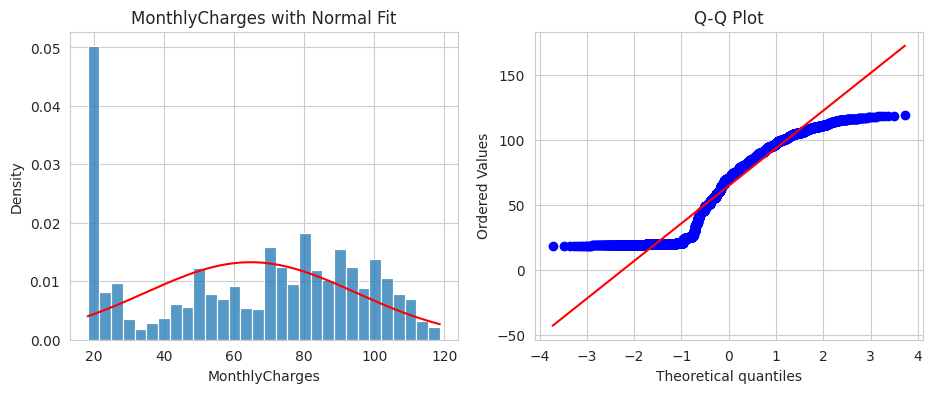

ShapiroResult(statistic=np.float64(0.9252848847824037), pvalue=np.float64(4.5773281491767354e-15))


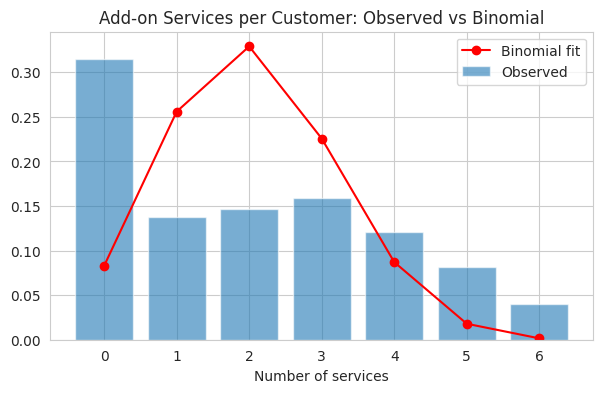

Chi-square p-value: 5.863038300673391e-258
TtestResult(statistic=np.float64(-31.57955051135377), pvalue=np.float64(7.99905796059022e-205), df=np.float64(7041.0))


In [6]:
# Continuous: MonthlyCharges, with skewness/kurtosis and a normal fit
x = df_clean["MonthlyCharges"]
print("Mean", x.mean(), "Median", x.median(), "Std", x.std(),
      "Skew", stats.skew(x), "Kurtosis", stats.kurtosis(x))

fig, ax = plt.subplots(1, 2, figsize=(11,4))
sns.histplot(x, stat="density", bins=30, ax=ax[0])
xs = np.linspace(x.min(), x.max(), 200)
ax[0].plot(xs, stats.norm.pdf(xs, x.mean(), x.std()), "r")
ax[0].set_title("MonthlyCharges with Normal Fit")
stats.probplot(x, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q Plot")
plt.savefig("images/dist_continuous.png", dpi=150, bbox_inches="tight"); plt.show()
print(stats.shapiro(x.sample(500, random_state=1)))   # normality test

# Discrete: number of add-on services per customer vs Binomial
services = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
n_serv = (df_clean[services] == "Yes").sum(axis=1)
p = n_serv.mean() / len(services)
vals = np.arange(0, len(services)+1)
plt.figure(figsize=(7,4))
plt.bar(vals, n_serv.value_counts(normalize=True).reindex(vals, fill_value=0), alpha=.6, label="Observed")
plt.plot(vals, stats.binom.pmf(vals, len(services), p), "ro-", label="Binomial fit")
plt.title("Add-on Services per Customer: Observed vs Binomial")
plt.xlabel("Number of services"); plt.legend()
plt.savefig("images/dist_discrete.png", dpi=150, bbox_inches="tight"); plt.show()

# Bivariate: chi-square test (categorical) and t-test (numeric)
ct = pd.crosstab(df_clean["Contract"], df_clean["Churn"])
print("Chi-square p-value:", stats.chi2_contingency(ct)[1])
print(stats.ttest_ind(df_clean[df_clean.Churn=="Yes"]["tenure"],
                      df_clean[df_clean.Churn=="No"]["tenure"]))

In [7]:
df_m = df_clean.copy()
yes_no = ["Partner","Dependents","PhoneService","MultipleLines","OnlineSecurity","OnlineBackup",
          "DeviceProtection","TechSupport","StreamingTV","StreamingMovies","PaperlessBilling","Churn"]
for c in yes_no:
    df_m[c] = (df_m[c] == "Yes").astype(int)
df_m["gender"] = (df_m["gender"] == "Male").astype(int)
df_m = pd.get_dummies(df_m, columns=["InternetService","Contract","PaymentMethod"],
                      drop_first=True, dtype=int)

X = df_m.drop(columns="Churn"); y = df_m["Churn"]

# 70 / 15 / 15 stratified split
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)
print(X_tr.shape, X_val.shape, X_te.shape)

# Scale numeric columns (fit on TRAIN only, to avoid data leakage)
num_cols = ["tenure","MonthlyCharges","TotalCharges"]
sc = StandardScaler().fit(X_tr[num_cols])
for d in (X_tr, X_val, X_te):
    d[num_cols] = sc.transform(d[num_cols])

(4930, 23) (1056, 23) (1057, 23)


In [8]:
cw = compute_class_weight("balanced", classes=np.array([0,1]), y=y_tr)
class_weight = {0: cw[0], 1: cw[1]}          # handles class imbalance

def build(units, dropout, lr):
    m = keras.Sequential([
        layers.Input(shape=(X_tr.shape[1],)),
        layers.Dense(units, activation="relu"), layers.Dropout(dropout),
        layers.Dense(units//2, activation="relu"), layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
grid = [(32,0.2,1e-3), (64,0.3,1e-3), (64,0.3,5e-4), (128,0.4,1e-3)]
best = None
for units, dr, lr in grid:
    m = build(units, dr, lr)
    h = m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=100, batch_size=32,
              class_weight=class_weight, callbacks=[es], verbose=0)
    v_auc = max(h.history["val_auc"])
    print(f"units={units}, dropout={dr}, lr={lr} -> best val AUC = {v_auc:.4f}")
    if best is None or v_auc > best[0]:
        best = (v_auc, m, h, (units, dr, lr))
_, model, history, best_params = best
print("Best hyperparameters:", best_params)
model.summary()

units=32, dropout=0.2, lr=0.001 -> best val AUC = 0.8468
units=64, dropout=0.3, lr=0.001 -> best val AUC = 0.8450
units=64, dropout=0.3, lr=0.0005 -> best val AUC = 0.8427
units=128, dropout=0.4, lr=0.001 -> best val AUC = 0.8470
Best hyperparameters: (128, 0.4, 0.001)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 128)            │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,181 (133.52 KB)

 Trainable params: 11,393 (44.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,788 (89.02 KB)

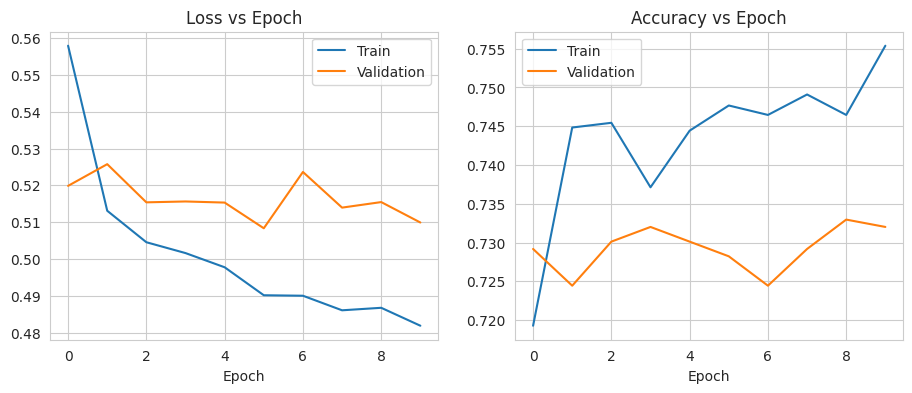

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
              precision    recall  f1-score   support

    No churn       0.91      0.72      0.81       776
       Churn       0.51      0.80      0.63       281

    accuracy                           0.75      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.81      0.75      0.76      1057



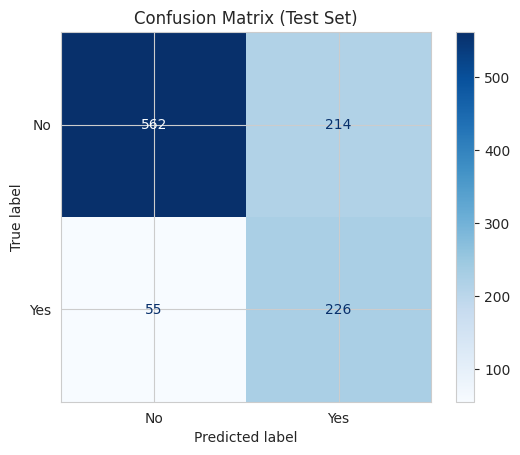

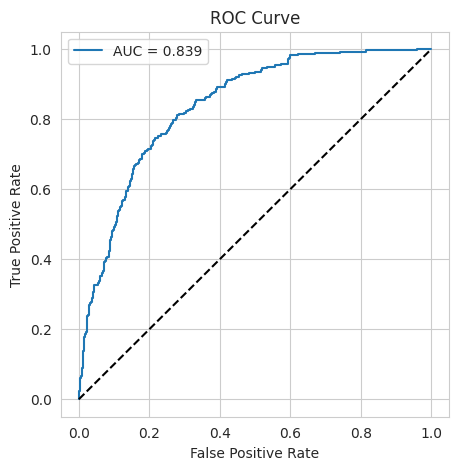

In [9]:
# Loss and accuracy vs epoch
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(history.history["loss"], label="Train"); ax[0].plot(history.history["val_loss"], label="Validation")
ax[0].set_title("Loss vs Epoch"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="Train"); ax[1].plot(history.history["val_accuracy"], label="Validation")
ax[1].set_title("Accuracy vs Epoch"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.savefig("images/r1_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# Test predictions
prob = model.predict(X_te).ravel(); pred = (prob >= 0.5).astype(int)
print(classification_report(y_te, pred, target_names=["No churn","Churn"]))

# Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["No","Yes"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.savefig("images/r2_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

# ROC curve and AUC
fpr, tpr, _ = roc_curve(y_te, prob); auc = roc_auc_score(y_te, prob)
plt.figure(figsize=(5,5)); plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}"); plt.plot([0,1],[0,1],"k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve"); plt.legend()
plt.savefig("images/r3_roc.png", dpi=150, bbox_inches="tight"); plt.show()

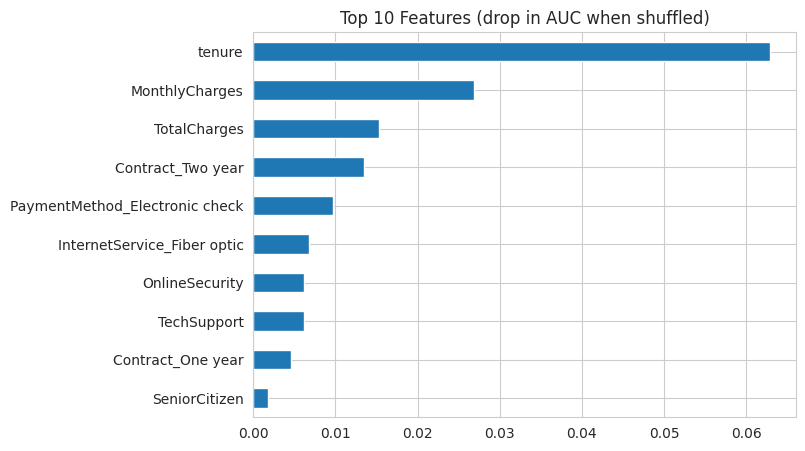

In [10]:
base = roc_auc_score(y_te, model.predict(X_te, verbose=0).ravel())
imp = {}
for col in X_te.columns:
    Xp = X_te.copy(); Xp[col] = np.random.permutation(Xp[col].values)
    imp[col] = base - roc_auc_score(y_te, model.predict(Xp, verbose=0).ravel())
imp = pd.Series(imp).sort_values(ascending=False).head(10)
imp[::-1].plot(kind="barh", figsize=(7,5), title="Top 10 Features (drop in AUC when shuffled)")
plt.savefig("images/r4_importance.png", dpi=150, bbox_inches="tight"); plt.show()

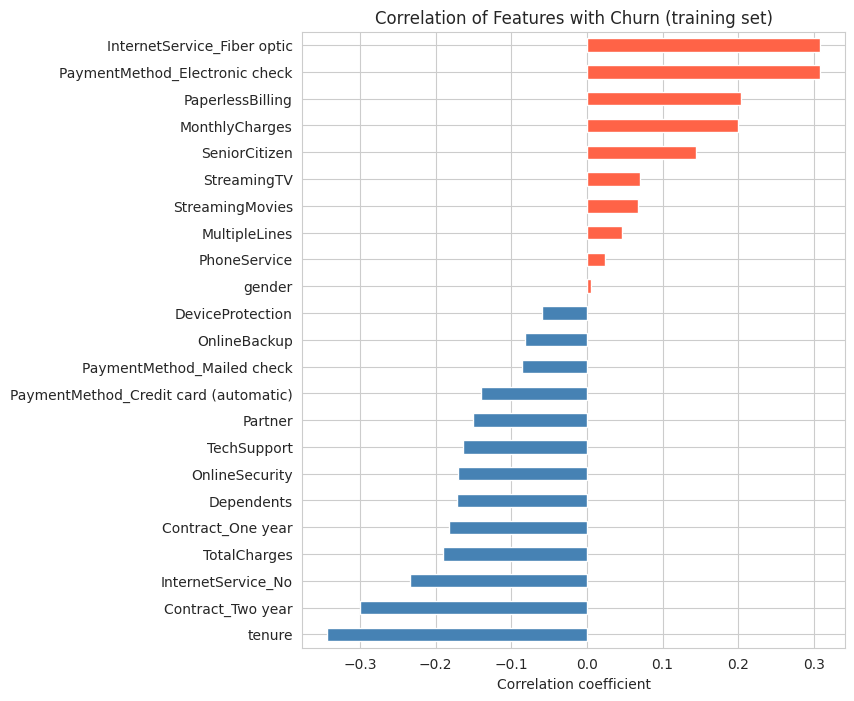

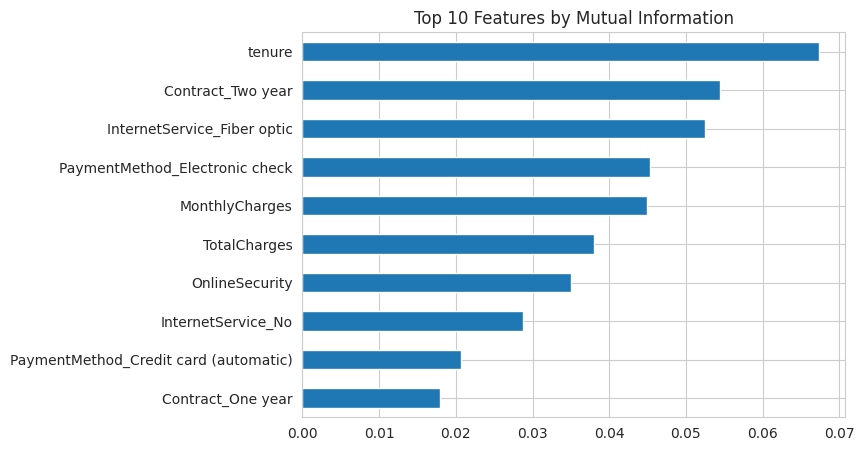

                  tenure  MonthlyCharges  TotalCharges
tenure          1.000000        0.258359      0.829845
MonthlyCharges  0.258359        1.000000      0.654016
TotalCharges    0.829845        0.654016      1.000000


In [11]:
from sklearn.feature_selection import mutual_info_classif

# 1) Correlation of every (encoded) feature with Churn
corr = pd.concat([X_tr, y_tr], axis=1).corr()["Churn"].drop("Churn").sort_values()
plt.figure(figsize=(7,8))
corr.plot(kind="barh", color=["tomato" if v > 0 else "steelblue" for v in corr])
plt.title("Correlation of Features with Churn (training set)")
plt.xlabel("Correlation coefficient")
plt.savefig("images/f1_corr_target.png", dpi=150, bbox_inches="tight"); plt.show()

# 2) Mutual information (captures non-linear relationships too)
mi = pd.Series(mutual_info_classif(X_tr, y_tr, random_state=42),
               index=X_tr.columns).sort_values(ascending=False)
mi.head(10)[::-1].plot(kind="barh", figsize=(7,5), title="Top 10 Features by Mutual Information")
plt.savefig("images/f2_mutual_info.png", dpi=150, bbox_inches="tight"); plt.show()

# 3) Multicollinearity check: tenure and TotalCharges are expected to be highly correlated
print(X_tr[["tenure","MonthlyCharges","TotalCharges"]].corr())

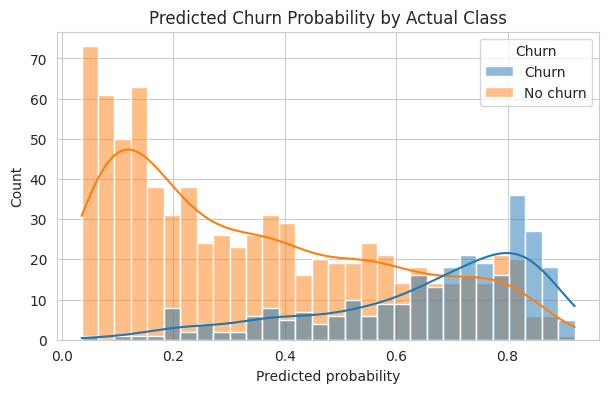

In [12]:
# Optional: predicted probability distribution by actual class
plt.figure(figsize=(7,4))
sns.histplot(x=prob, hue=y_te.map({0:"No churn",1:"Churn"}), bins=30, kde=True)
plt.title("Predicted Churn Probability by Actual Class"); plt.xlabel("Predicted probability")
plt.savefig("images/r5_prob_dist.png", dpi=150, bbox_inches="tight"); plt.show()